In [8]:
!pip install dash jupyter-dash folium plotly lxml html5lib
!wget -q "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv" -O dataset_part_2.csv

1.5: SpaceX API Data Collection
API Status Code: 525
⚠️ API returned 525 — using IBM cached dataset.
✅ Loaded cached API dataset: (107, 26)
Sample columns: ['fairings', 'links', 'static_fire_date_utc', 'static_fire_date_unix', 'tbd', 'net', 'window', 'rocket', 'success', 'details']
                                            fairings  \
0  {'reused': False, 'recovery_attempt': False, '...   
1  {'reused': False, 'recovery_attempt': False, '...   
2  {'reused': False, 'recovery_attempt': False, '...   

                                               links  \
0  {'patch': {'small': 'https://images2.imgbox.co...   
1  {'patch': {'small': 'https://images2.imgbox.co...   
2  {'patch': {'small': 'https://images2.imgbox.co...   

       static_fire_date_utc  static_fire_date_unix    tbd    net  window  \
0  2006-03-17T00:00:00.000Z           1.142554e+09  False  False     0.0   
1                      None                    NaN  False  False     0.0   
2                      None            

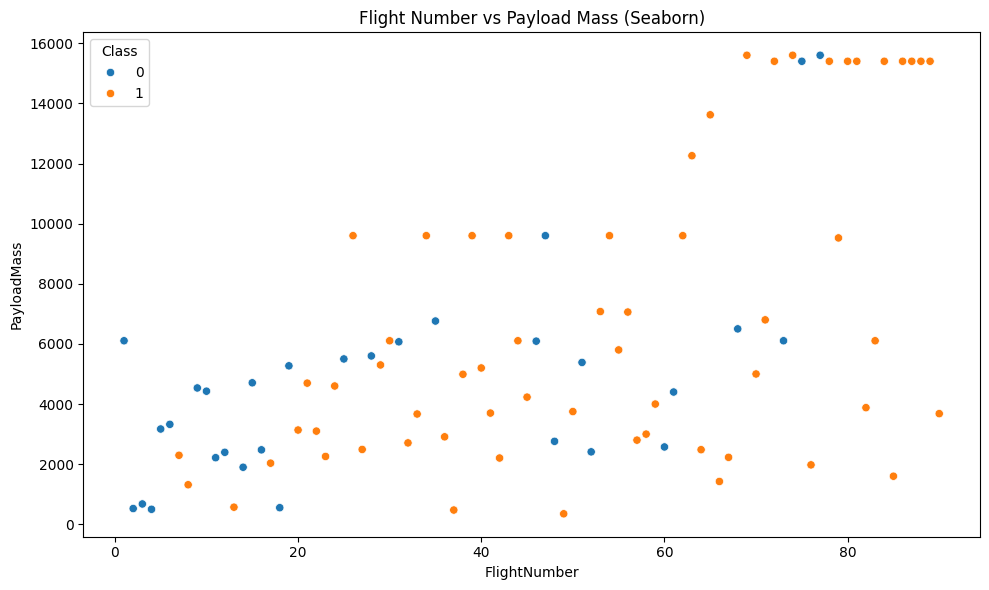


1.9 & 1.12: EDA with SQL

1. Launch sites + total payload
     LaunchSite   TotalPayload
0  CCAFS SLC 40  305151.428235
1    KSC LC 39A  167341.918824
2   VAFB SLC 4E   76953.000000

2. Avg payload for F9 v1.1
  AvgPayload
0       None

3. Drone ship landings
   DroneShipLandings
0                 49

4. Min payload per launch site (successful)
     LaunchSite  MinPayload
0  CCAFS SLC 40       350.0
1    KSC LC 39A      2490.0
2   VAFB SLC 4E       475.0

5. Yearly landing outcomes
    Year      Outcome  Total
0   2010    None None      1
1   2012    None None      1
2   2013  False Ocean      1
3   2013    None None      2
4   2014  False Ocean      1
5   2014    None None      3
6   2014   True Ocean      2
7   2015   False ASDS      2
8   2015    None ASDS      1
9   2015    None None      1
10  2015   True Ocean      1
11  2015    True RTLS      1
12  2016   False ASDS      2
13  2016    None ASDS      1
14  2016    True ASDS      4
15  2016    True RTLS      1
16  2017    None No


1.10 & 1.14: Plotly Dash — rendering inline


<IPython.core.display.Javascript object>


1.15: Predictive Analysis — Machine Learning
Training samples: 72
Test samples:     18
Features:         80

Logistic Regression Test Accuracy: 0.8333

SVM Best Params:   {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
SVM Best CV Score: 0.8181

Decision Tree Best Params: {'criterion': 'entropy', 'max_depth': 2}
Decision Tree Best CV:     0.8181

KNN Best Params:   {'n_neighbors': 4}
KNN Best CV Score: 0.7895

----------------------------------------
FINAL EVALUATION — Best Model
----------------------------------------
Best Model: Logistic Regression (CV score = 0.8333)

Confusion Matrix:
[[ 3  3]
 [ 0 12]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.50      0.67         6
           1       0.80      1.00      0.89        12

    accuracy                           0.83        18
   macro avg       0.90      0.75      0.78        18
weighted avg       0.87      0.83      0.81        18

Final Test Accuracy: 0.8333

-------

In [11]:
# ============================================================
# IBM DATA SCIENCE CAPSTONE - SPACEX PROJECT
# Complete Code for Sections 1.5 to 1.15 (Colab-ready, fixed)
# ============================================================

# ---------------- Imports ----------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup
import sqlite3
import folium
from folium.plugins import MarkerCluster
import plotly.express as px
from jupyter_dash import JupyterDash
from dash import dcc, html
from dash.dependencies import Input, Output

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import warnings
warnings.filterwarnings("ignore")


# ============================================================
# 1.5 — DATA COLLECTION: SpaceX API (with fallback)
# ============================================================
print("=" * 60)
print("1.5: SpaceX API Data Collection")
print("=" * 60)

spacex_url = "https://api.spacexdata.com/v4/launches/past"
api_ok = False

try:
    response = requests.get(spacex_url, timeout=15)
    print(f"API Status Code: {response.status_code}")

    if response.status_code == 200:
        api_data = pd.json_normalize(response.json())
        print(f"✅ Live API records fetched: {api_data.shape[0]}")
        print("Sample columns:", list(api_data.columns)[:10])
        print(api_data.head(3))
        api_ok = True
    else:
        print(f"⚠️ API returned {response.status_code} — using IBM cached dataset.")
except Exception as e:
    print(f"⚠️ API request failed: {e}")
    print("Falling back to the IBM-provided cached dataset.")

if not api_ok:
    cached_url = ("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
                  "IBM-DS0321EN-SkillsNetwork/datasets/API_call_spacex_api.json")
    try:
        api_data = pd.read_json(cached_url)
        if 'launches' in api_data.columns:
            api_data = pd.json_normalize(api_data['launches'])
        print(f"✅ Loaded cached API dataset: {api_data.shape}")
        print("Sample columns:", list(api_data.columns)[:10])
        print(api_data.head(3))
    except Exception as e:
        print(f"Could not load cached dataset: {e}")
        api_data = pd.DataFrame()


# ============================================================
# 1.6 — DATA COLLECTION: Web Scraping Wikipedia (fixed)
# ============================================================
print("\n" + "=" * 60)
print("1.6: Web Scraping Data Collection")
print("=" * 60)

wiki_url = ("https://en.wikipedia.org/wiki/"
            "List_of_Falcon_9_and_Falcon_Heavy_launches")

# ✅ Wikipedia requires a real user-agent, or it returns 403
headers = {
    "User-Agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                   "AppleWebKit/537.36 (KHTML, like Gecko) "
                   "Chrome/120.0.0.0 Safari/537.36")
}

resp = requests.get(wiki_url, headers=headers, timeout=20)
print(f"Wikipedia Status Code: {resp.status_code}")

if resp.status_code == 200:
    html_data = resp.text
    soup = BeautifulSoup(html_data, "html.parser")

    # Try the specific class first, then fallbacks
    launch_tables = soup.find_all('table', class_='wikitable plainrowheaders collapsible')
    if len(launch_tables) == 0:
        print("⚠️ Specific class failed — using all wikitables.")
        launch_tables = soup.find_all('table', class_='wikitable')
    if len(launch_tables) == 0:
        print("⚠️ Still none — grabbing every <table>.")
        launch_tables = soup.find_all('table')

    print(f"Found {len(launch_tables)} launch tables on Wikipedia.")

    if len(launch_tables) > 0:
        header_rows = launch_tables[0].find_all('th')
        column_names = [th.get_text(strip=True) for th in header_rows if th.get_text(strip=True)]
        print("Wikipedia table columns:", column_names)

        first_row = launch_tables[0].find_all('tr')
        if len(first_row) > 1:
            print("First data row preview:",
                  [td.get_text(strip=True) for td in first_row[1].find_all('td')])

    # Optional: parse with pandas directly from the HTML string
    try:
        tables = pd.read_html(html_data)
        print(f"\n✅ pandas.read_html found {len(tables)} tables.")
        # Print the largest launch table
        for i, t in enumerate(tables):
            if t.shape[0] > 50 and t.shape[1] > 5:
                print(f"\n→ Main launch table: index #{i}, shape {t.shape}")
                print("Columns:", list(t.columns))
                print(t.head(3))
                break
    except Exception as e:
        print(f"pandas.read_html failed: {e}")
else:
    print(f"⚠️ Wikipedia returned {resp.status_code} — skipping scraping.")
    column_names = []


# ============================================================
# 1.7 — DATA WRANGLING
# ============================================================
print("\n" + "=" * 60)
print("1.7: Data Wrangling")
print("=" * 60)

try:
    df = pd.read_csv("dataset_part_2.csv")
    if 'Year' not in df.columns and 'Date' in df.columns:
        df['Year'] = pd.to_datetime(df['Date']).dt.year
    print(f"Loaded real dataset: {df.shape}")
except FileNotFoundError:
    print("dataset_part_2.csv not found — using synthetic fallback.")
    np.random.seed(42)
    df = pd.DataFrame({
        'FlightNumber': range(1, 101),
        'PayloadMass': np.random.randint(500, 15000, 100),
        'LaunchSite': np.random.choice(
            ['CCAFS SLC 40', 'KSC LC 39A', 'VAFB SLC 4E'], 100),
        'Class': np.random.choice([0, 1], 100),
        'BoosterVersion': np.random.choice(
            ['F9 v1.0', 'F9 v1.1', 'F9 Full Thrust'], 100),
        'Outcome': np.random.choice(
            ['True ASDS', 'True RTLS', 'False ASDS', 'None ASDS'], 100),
        'Year': np.random.choice(range(2010, 2021), 100)
    })

df['PayloadMass'] = df['PayloadMass'].fillna(df['PayloadMass'].median())
print("Data wrangling complete.")
print(df.head())


# ============================================================
# 1.8 & 1.11 — EDA WITH VISUALIZATION
# ============================================================
print("\n" + "=" * 60)
print("1.8 & 1.11: EDA with Visualizations")
print("=" * 60)

# Scatter: Flight Number vs Payload Mass
px.scatter(df, x='FlightNumber', y='PayloadMass', color='Class',
           title='Flight Number vs Payload Mass').show()

# Bar: Launch Site success rate
site_success = df.groupby('LaunchSite')['Class'].mean().reset_index()
px.bar(site_success, x='LaunchSite', y='Class',
       title='Launch Site vs Success Rate').show()

# Line: Yearly success trend
yearly = df.groupby('Year')['Class'].mean().reset_index()
px.line(yearly, x='Year', y='Class',
        title='Yearly Launch Success Trend').show()

# Seaborn cross-check
plt.figure(figsize=(10, 6))
sns.scatterplot(x='FlightNumber', y='PayloadMass', hue='Class', data=df)
plt.title('Flight Number vs Payload Mass (Seaborn)')
plt.tight_layout()
plt.show()


# ============================================================
# 1.9 & 1.12 — EDA WITH SQL
# ============================================================
print("\n" + "=" * 60)
print("1.9 & 1.12: EDA with SQL")
print("=" * 60)

conn = sqlite3.connect(':memory:')
df.to_sql('SPACEX_TABLE', conn, index=False, if_exists='replace')

queries = {
    "1. Launch sites + total payload":
        "SELECT LaunchSite, SUM(PayloadMass) AS TotalPayload "
        "FROM SPACEX_TABLE GROUP BY LaunchSite;",

    "2. Avg payload for F9 v1.1":
        "SELECT AVG(PayloadMass) AS AvgPayload "
        "FROM SPACEX_TABLE WHERE BoosterVersion='F9 v1.1';",

    "3. Drone ship landings":
        "SELECT COUNT(*) AS DroneShipLandings "
        "FROM SPACEX_TABLE WHERE Outcome LIKE '%ASDS%';",

    "4. Min payload per launch site (successful)":
        "SELECT LaunchSite, MIN(PayloadMass) AS MinPayload "
        "FROM SPACEX_TABLE WHERE Class=1 GROUP BY LaunchSite;",

    "5. Yearly landing outcomes":
        "SELECT Year, Outcome, COUNT(*) AS Total "
        "FROM SPACEX_TABLE GROUP BY Year, Outcome ORDER BY Year;",
}

for label, q in queries.items():
    print(f"\n{label}")
    try:
        print(pd.read_sql(q, conn))
    except Exception as e:
        print(f"Query error: {e}")

conn.close()


# ============================================================
# 1.10 & 1.13 — INTERACTIVE VISUAL ANALYTICS: Folium Map
# ============================================================
print("\n" + "=" * 60)
print("1.10 & 1.13: Folium Map")
print("=" * 60)

launch_sites_coords = {
    'CCAFS SLC 40': [28.5618571, -80.577366],
    'KSC LC 39A':   [28.5733056, -80.646895],
    'VAFB SLC 4E':  [34.632834,  -120.610746]
}

site_map = folium.Map(location=[29.559684, -95.083097], zoom_start=4)
marker_cluster = MarkerCluster().add_to(site_map)

for site, coords in launch_sites_coords.items():
    folium.Marker(
        coords, popup=site,
        icon=folium.Icon(color='blue', icon='info-sign')
    ).add_to(site_map)

for _, row in df.iterrows():
    if row['LaunchSite'] in launch_sites_coords:
        coords = launch_sites_coords[row['LaunchSite']]
        color = 'green' if row['Class'] == 1 else 'red'
        folium.CircleMarker(
            location=coords, radius=5,
            color=color, fill=True, fill_color=color,
            popup=f"Flight {row['FlightNumber']}: "
                  f"{'Success' if row['Class']==1 else 'Failure'}"
        ).add_to(marker_cluster)

site_map.save("spacex_launch_map.html")
print("Map saved: spacex_launch_map.html")

from IPython.display import display, IFrame
display(IFrame("spacex_launch_map.html", width=800, height=500))


# ============================================================
# 1.10 & 1.14 — INTERACTIVE VISUAL ANALYTICS: Plotly Dash (Colab)
# ============================================================
print("\n" + "=" * 60)
print("1.10 & 1.14: Plotly Dash — rendering inline")
print("=" * 60)

df_dash = df.copy()

app = JupyterDash(__name__)

app.layout = html.Div([
    html.H1("SpaceX Launch Records Dashboard",
            style={"textAlign": "center", "color": "#503D36", "fontSize": 32}),
    dcc.Dropdown(
        id="site-dropdown",
        options=[{"label": "All Sites", "value": "ALL"}] +
                [{"label": s, "value": s} for s in df_dash["LaunchSite"].unique()],
        value="ALL",
        placeholder="Select a Launch Site here",
        searchable=True
    ),
    html.Br(),
    dcc.Graph(id="success-pie-chart"),
    html.Br(),
    dcc.RangeSlider(
        id="payload-slider",
        min=0, max=10000, step=1000,
        marks={0: "0", 2500: "2500", 5000: "5000",
               7500: "7500", 10000: "10000"},
        value=[0, 10000]
    ),
    dcc.Graph(id="success-payload-scatter-chart")
])


@app.callback(
    Output("success-pie-chart", "figure"),
    Input("site-dropdown", "value"))
def get_pie_chart(entered_site):
    if entered_site == "ALL":
        return px.pie(df_dash, values="Class", names="LaunchSite",
                      title="Total Success Launches By Site")
    filtered = df_dash[df_dash["LaunchSite"] == entered_site]
    filtered = filtered.groupby("Class").size().reset_index(name="counts")
    return px.pie(filtered, values="counts", names="Class",
                  title=f"Success Launches for site {entered_site}")


@app.callback(
    Output("success-payload-scatter-chart", "figure"),
    [Input("site-dropdown", "value"),
     Input("payload-slider", "value")])
def get_scatter_chart(entered_site, payload_range):
    low, high = payload_range
    filtered = df_dash[(df_dash["PayloadMass"] >= low) &
                       (df_dash["PayloadMass"] <= high)]
    if entered_site != "ALL":
        filtered = filtered[filtered["LaunchSite"] == entered_site]
    return px.scatter(filtered, x="PayloadMass", y="Class",
                      color="BoosterVersion",
                      title=f"Payload vs Success — {entered_site}")


# ✅ FIXED: run_server → run (Dash 3.0 compatible)
try:
    app.run(mode="inline", debug=False)
except AttributeError:
    # Older Dash fallback
    app.run_server(mode="inline", debug=False)


# ============================================================
# 1.15 — PREDICTIVE ANALYSIS (Machine Learning)
# ============================================================
print("\n" + "=" * 60)
print("1.15: Predictive Analysis — Machine Learning")
print("=" * 60)

try:
    df_ml = pd.read_csv("dataset_part_2.csv")
    if 'Year' not in df_ml.columns and 'Date' in df_ml.columns:
        df_ml['Year'] = pd.to_datetime(df_ml['Date']).dt.year
except FileNotFoundError:
    df_ml = df.copy()

# ---------------- Feature Preparation ----------------
features = df_ml[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite',
                  'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad',
                  'Block', 'ReusedCount', 'Serial']]
X = pd.get_dummies(features,
                   columns=['Orbit', 'LaunchSite', 'LandingPad', 'Serial'])
y = df_ml['Class'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples:     {X_test.shape[0]}")
print(f"Features:         {X_train.shape[1]}")


# ---------------- Model 1: Logistic Regression ----------------
lr = LogisticRegression(max_iter=1000).fit(X_train, y_train)
lr_acc = lr.score(X_test, y_test)
print(f"\nLogistic Regression Test Accuracy: {lr_acc:.4f}")


# ---------------- Model 2: SVM with GridSearch ----------------
grid_svm = GridSearchCV(
    SVC(),
    {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf'], 'gamma': ['scale', 'auto']},
    cv=5
).fit(X_train, y_train)
print(f"\nSVM Best Params:   {grid_svm.best_params_}")
print(f"SVM Best CV Score: {grid_svm.best_score_:.4f}")


# ---------------- Model 3: Decision Tree with GridSearch ----------------
grid_tree = GridSearchCV(
    DecisionTreeClassifier(),
    {'max_depth': [2, 4, 6, 8, 10], 'criterion': ['gini', 'entropy']},
    cv=5
).fit(X_train, y_train)
print(f"\nDecision Tree Best Params: {grid_tree.best_params_}")
print(f"Decision Tree Best CV:     {grid_tree.best_score_:.4f}")


# ---------------- Model 4: KNN with GridSearch ----------------
grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    {'n_neighbors': list(range(1, 11))},
    cv=5
).fit(X_train, y_train)
print(f"\nKNN Best Params:   {grid_knn.best_params_}")
print(f"KNN Best CV Score: {grid_knn.best_score_:.4f}")


# ---------------- Final Evaluation: Best Model ----------------
print("\n" + "-" * 40)
print("FINAL EVALUATION — Best Model")
print("-" * 40)

scores = {
    "Logistic Regression": lr_acc,
    "SVM":                 grid_svm.best_score_,
    "Decision Tree":       grid_tree.best_score_,
    "KNN":                 grid_knn.best_score_,
}
best_name = max(scores, key=scores.get)
print(f"Best Model: {best_name} (CV score = {scores[best_name]:.4f})")

best_models = {
    "Logistic Regression": lr,
    "SVM":                 grid_svm.best_estimator_,
    "Decision Tree":       grid_tree.best_estimator_,
    "KNN":                 grid_knn.best_estimator_,
}
best_model = best_models[best_name]
y_pred = best_model.predict(X_test)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print(f"Final Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")


# ---------------- Model Comparison Summary ----------------
print("\n" + "-" * 40)
print("MODEL COMPARISON SUMMARY")
print("-" * 40)
summary = pd.DataFrame({
    'Model': list(scores.keys()),
    'Score': list(scores.values())
}).sort_values('Score', ascending=False)
print(summary.to_string(index=False))


# ============================================================
# DONE
# ============================================================
print("\n" + "=" * 60)
print("ALL SECTIONS 1.5 – 1.15 COMPLETE")
print("=" * 60)